In [1]:
# Imports

import pandas as pd
import numpy as np
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

In [2]:
# File pahts

FILE_PATH = "data_strawberries.xlsx"
MATERIALS_SHEET = "materials"
FERT_INFO_SHEET = "fert info"
CONSTANTS_SHEET = "constants"
DATA_SHEET = "data"
OUTPUT_XLSX = "strawberry_lca_results.xlsx"

In [8]:
# -------------------------
# Constants and Emission Factors
# Load from YAML — single source of truth
# -------------------------

import yaml
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

# Path to YAML — adjust depending on whether running locally or in Colab
# Option A: Running in Google Colab (Drive mounted)
yaml_path = Path('/content/drive/MyDrive/strawberries/emission_factors.yaml')

# Option B: Running locally (uncomment if needed)
# yaml_path = Path('data/external/emission_factors.yaml')

with open(yaml_path, 'r') as f:
    ef = yaml.safe_load(f)

# --- GWP values ---
GWP100_CO2  = ef['gwp_ar6']['co2']           # 1.0
GWP100_CH4  = ef['gwp_ar6']['ch4_fossil']    # 29.8
GWP100_N2O  = ef['gwp_ar6']['n2o']           # 273

# --- Direct N2O ---
N2O_EF_DIRECT       = ef['direct_n2o']['ef1_coir']       # 0.005
N2O_EF_DIRECT_IPCC  = ef['direct_n2o']['ef1_ipcc_wet']   # 0.016

# --- Indirect N2O ---
N2O_EF_INDIRECT_VOLATILISATION = ef['volatilisation']['ef4']   # 0.014
N2O_EF_INDIRECT_LEACHING       = ef['leaching']['ef5']          # 0.011

# --- Fractions ---
FRAC_GASF         = ef['volatilisation']['frac_gasf_drip']       # 0.02
FRAC_LEACH        = ef['leaching']['frac_leach_semiclosed']      # 0.10
FRAC_LEACH_IPCC   = ef['leaching']['frac_leach_ipcc']            # 0.24
FRAC_LEACH_CLOSED = ef['leaching']['frac_leach_closed']          # 0.02

# --- Fertiliser production ---
EF_N_PRODUCTION    = ef['fertiliser_production']['ef_n_production']    # 8.66
EF_P2O5_PRODUCTION = ef['fertiliser_production']['ef_p2o5_production'] # 1.46
EF_K2O_PRODUCTION  = ef['fertiliser_production']['ef_k2o_production']  # 0.307

# --- Energy ---
EF_ELECTRICITY_UK  = ef['energy']['ef_electricity_uk']   # 0.233
EF_ELECTRICITY_NL  = ef['energy']['ef_electricity_nl']   # 0.379
EF_ELECTRICITY_ES  = ef['energy']['ef_electricity_es']   # 0.200
EF_ELECTRICITY_IT  = ef['energy']['ef_electricity_it']   # 0.350
EF_ELECTRICITY_EU  = ef['energy']['ef_electricity_eu']   # 0.275
EF_DIESEL          = ef['energy']['ef_diesel']            # 0.200

# --- Materials ---
EF_PLASTIC  = ef['materials']['ef_plastic']           # 1.8
EF_FLEECE   = ef['materials']['ef_fleece']            # 2.1
EF_COIR     = ef['materials']['ef_coir']              # 0.15

# --- Transport ---
EF_TRANSPORT_ROAD       = ef['transport']['ef_road_freight']              # 0.0962
TRANSPORT_DISTANCE_NL   = ef['transport']['distances_km']['netherlands']  # 707
TRANSPORT_DISTANCE_ES   = ef['transport']['distances_km']['spain']        # 1844
TRANSPORT_DISTANCE_IT   = ef['transport']['distances_km']['italy']        # 1784
SEEDLING_WEIGHT_KG      = ef['transport']['seedling_weight_kg']           # 0.178

# --- Water ---
EF_IRRIGATION_WATER = ef['water']['ef_irrigation']    # 0.001

# --- Sensitivity scenarios ---
SENSITIVITY_SCENARIOS = ef['sensitivity_scenarios']

# --- Molecular weight conversion N2O-N to N2O ---
N2O_TO_N2ON = 44 / 28  # = 1.5714

print("✓ All parameters loaded from emission_factors.yaml")
print(f"  EF1={N2O_EF_DIRECT}, FRAC_GASF={FRAC_GASF}, FRAC_LEACH={FRAC_LEACH}, GWP_N2O={GWP100_N2O}")

Mounted at /content/drive
✓ All parameters loaded from emission_factors.yaml
  EF1=0.005, FRAC_GASF=0.02, FRAC_LEACH=0.1, GWP_N2O=273


In [9]:
# Validate data structure

def validate_data_structure(df, required_columns):
    """Validate that required columns exist in the DataFrame"""
    missing_cols = [col for col in required_columns if col not in df.columns]
    if missing_cols:
        print(f"Warning: Missing columns: {missing_cols}")
        return False
    return True

In [10]:
# Get country electricity

def get_country_electricity_ef(country):
    "Get electricity emission factor based on country"
    country_lower = str(country).lower()
    if 'uk' in country_lower or 'britain' in country_lower:
        return EF_ELECTRICITY_UK
    elif 'holland' in country_lower or 'netherlands' in country_lower:
        return EF_ELECTRICITY_NL
    elif 'spain' in country_lower:
        return EF_ELECTRICITY_ES
    elif 'italy' in country_lower:
        return EF_ELECTRICITY_IT
    else:
        print(f"Warning: Unknown country '{country}', using EU average")
        return EF_ELECTRICITY_EU  # Default to EU average

In [ ]:
# Fertiliser production emissions

def calculate_fertiliser_production_emissions(n_kg, p2o5_kg, k2o_kg):
    """Calculate CO2 emissions from fertiliser production"""
    co2_n = n_kg * EF_N_PRODUCTION
    co2_p2o5 = p2o5_kg * EF_P2O5_PRODUCTION
    co2_k2o = k2o_kg * EF_K2O_PRODUCTION

    return co2_n + co2_p2o5 + co2_k2o

In [ ]:
# N2O emissions from fertiliser

def calculate_n2o_emissions_from_fertiliser(n_applied_kg):
    """Calculate N2O emissions from from fertiliser application using IPCC Tier 1 method
      Uses system-appropriate leaching fraction (FRAC_LEACH = 0.10) for
      tabletop coir production, rather than IPCC soil default (0.24). """


    n2o_direct = n_applied_kg * N2O_EF_DIRECT # Direct emissions from soil

    # Indirect emissions from volatilisation
    n2o_volatilised = n_applied_kg * FRAC_GASF
    n2o_vol = n2o_volatilised * N2O_EF_INDIRECT_VOLATILISATION

    # Indirect emissions from leaching
    n2o_leach = n_applied_kg * FRAC_LEACH * N2O_EF_INDIRECT_LEACHING

    # Convert N2O-N to N2O and then CO2-eq

    n2o_direct_kg = n2o_direct * N2O_TO_N2ON
    n2o_vol_kg = n2o_vol * N2O_TO_N2ON
    n2o_leach_kg = n2o_leach * N2O_TO_N2ON

    total_n2o_kg = n2o_direct_kg + n2o_vol_kg + n2o_leach_kg
    total_co2_eq = total_n2o_kg * GWP100_N2O

    return {
        'n2o_direct_kg': n2o_direct_kg,
        'n2o_vol_kg': n2o_vol_kg,
        'n2o_leach_kg': n2o_leach_kg,
        'total_n2o_kg': total_n2o_kg,
        'total_co2_eq': total_co2_eq

    }


In [ ]:
# Energy emissions

def calculate_energy_emissions(electricity_kWh, diesel_l, country):
  """Calculate emissions from energy use"""
  ef_electricity = get_country_electricity_ef(country)

  co2_electricity = electricity_kWh * ef_electricity
  co2_diesel = diesel_l * EF_DIESEL

  return {
      'co2_electricity': co2_electricity,
      'co2_diesel': co2_diesel,
      'total_energy_co2eq_kg': co2_electricity + co2_diesel
  }

In [ ]:
# Material emissions

def calculate_materials_emissions(plastic_m2, fleece_m2, coir_kg):
    """Calculate emissions from material inputs"""
    # Convert areas to approximate weights (typical material densities)
    plastic_kg = plastic_m2 * 0.15  # ~150g/m² for greenhouse plastic
    fleece_kg = fleece_m2 * 0.08   # ~80g/m² for fleece

    co2_plastic = plastic_kg * EF_PLASTIC
    co2_fleece = fleece_kg * EF_FLEECE
    co2_coir = coir_kg * EF_COIR

    return {
        'plastic_co2eq_kg': co2_plastic,
        'fleece_co2eq_kg': co2_fleece,
        'coir_co2eq_kg': co2_coir,
        'total_materials_co2eq_kg': co2_plastic + co2_fleece + co2_coir
    }


In [ ]:
# Water emissions

def calculate_water_emissions(irrigation_m3, spray_water_m3):
    """Calculate emissions from water use"""
    total_water_m3 = irrigation_m3 + spray_water_m3
    co2_water = total_water_m3 * EF_IRRIGATION_WATER

    return {
        'total_water_m3': total_water_m3,
        'water_co2eq_kg': co2_water
    }


In [ ]:
# Transport emissions

def calculate_seedling_transport_emissions(seedlings_nl=0, seedlings_es=0, seedlings_it=0):
    """
    Calculate CO2-eq emissions from seedling transport.

    References:
    -----------
    Transport distances: IMPARGO HGV Route Planner (accessed 2024)
    Emission factors: ecoinvent v3.x, lorry 16-32t EURO5 {RER}
    """

    # Calculate mass transported from each country (tonnes)
    mass_nl_tonnes = (seedlings_nl * SEEDLING_WEIGHT_KG) / 1000
    mass_es_tonnes = (seedlings_es * SEEDLING_WEIGHT_KG) / 1000
    mass_it_tonnes = (seedlings_it * SEEDLING_WEIGHT_KG) / 1000
    total_mass_tonnes = mass_nl_tonnes + mass_es_tonnes + mass_it_tonnes

    # Calculate tonne-kilometres (tkm) for each route
    tkm_nl = mass_nl_tonnes * TRANSPORT_DISTANCE_NL
    tkm_es = mass_es_tonnes * TRANSPORT_DISTANCE_ES
    tkm_it = mass_it_tonnes * TRANSPORT_DISTANCE_IT
    total_tkm = tkm_nl + tkm_es + tkm_it

    # Calculate emissions (kg CO2-eq)
    co2eq_nl = tkm_nl * EF_TRANSPORT_ROAD
    co2eq_es = tkm_es * EF_TRANSPORT_ROAD
    co2eq_it = tkm_it * EF_TRANSPORT_ROAD
    total_co2eq = co2eq_nl + co2eq_es + co2eq_it

    # Calculate totals
    total_seedlings = seedlings_nl + seedlings_es + seedlings_it

    return {
        # Seedling counts
        'seedlings_nl': seedlings_nl,
        'seedlings_es': seedlings_es,
        'seedlings_it': seedlings_it,
        'seedlings_total': total_seedlings,

        # Mass (tonnes)
        'mass_nl_tonnes': mass_nl_tonnes,
        'mass_es_tonnes': mass_es_tonnes,
        'mass_it_tonnes': mass_it_tonnes,
        'mass_total_tonnes': total_mass_tonnes,

        # Transport activity (tkm)
        'tkm_nl': tkm_nl,
        'tkm_es': tkm_es,
        'tkm_it': tkm_it,
        'tkm_total': total_tkm,

        # Emissions (kg CO2-eq)
        'co2eq_nl': co2eq_nl,
        'co2eq_es': co2eq_es,
        'co2eq_it': co2eq_it,
        'transport_co2eq_kg': total_co2eq,

        # Contribution analysis (%)
        'pct_seedlings_nl': (seedlings_nl / total_seedlings * 100) if total_seedlings > 0 else 0,
        'pct_seedlings_es': (seedlings_es / total_seedlings * 100) if total_seedlings > 0 else 0,
        'pct_seedlings_it': (seedlings_it / total_seedlings * 100) if total_seedlings > 0 else 0,
        'pct_tkm_nl': (tkm_nl / total_tkm * 100) if total_tkm > 0 else 0,
        'pct_tkm_es': (tkm_es / total_tkm * 100) if total_tkm > 0 else 0,
        'pct_tkm_it': (tkm_it / total_tkm * 100) if total_tkm > 0 else 0
    }

In [ ]:
# load the data

def load_strawberry_data(file_path):
  """ load and validate production data"""
  try:
    df = pd.read_excel(file_path, sheet_name=DATA_SHEET)

    try:
      materials_df = pd.read_excel(file_path, sheet_name=MATERIALS_SHEET)
    except:
      materials_df = None
      print(f"Could not load {MATERIALS_SHEET} sheet")
    try:
      constants_df = pd.read_excel(file_path, sheet_name=CONSTANTS_SHEET)
    except:
      constants_df = None
      print(f"Could not load {CONSTANTS_SHEET} sheet")

    return df, materials_df, constants_df

  except Exception as e:
        print(f"Error loading data: {e}")
        return None, None, None

In [ ]:
# Process the data

def process_strawberry_lca(df):
  """Main calculation function"""
  results = []

  for idx, row in df.iterrows():
    #extract basic information
      try:
          year = row.get('Year', 'Unknown')
          system = row.get('system', 'Unknown')
          country = row.get('country', 'Unknown')
          variety = row.get('variety', 'Unknown')
          location = row.get('location', 'Unknown')
          area_ha = row.get('area', 0) or 0
          yield_kg = row.get('yield_kg', 0) or 0

          # Skip if no area or yield data
          if area_ha <= 0 or yield_kg <= 0:
              continue

          # Extract fertiliser data (assuming column structure from analysis)
          # Looking for total fertiliser nutrients applied
          total_n_kg = 0
          total_p2o5_kg = 0
          total_k2o_kg = 0

          # Get fertiliser totals from columns
          #Adjust column names
          for col in df.columns:
              col_lower = str(col).lower()
              if 'total fert' in col_lower and 'n' in col_lower:
                  total_n_kg = row.get(col, 0)
              elif 'total fert' in col_lower and 'p2o5' in col_lower:
                  total_p2o5_kg = row.get(col, 0)
              elif 'total fert' in col_lower and 'k2o' in col_lower:
                  total_k2o_kg = row.get(col, 0)

          # If totals not found, sum individual fertiliser applications
          if total_n_kg == 0:
             n_cols = [col for col in df.columns if 'as n kg' in str(col).lower()]
             total_n_kg = sum([row.get(col, 0) or 0 for col in n_cols])

          if total_p2o5_kg == 0:
             p_cols = [col for col in df.columns if 'as p2o5 kg' in str(col).lower()]
             total_p2o5_kg = sum([row.get(col, 0) or 0 for col in p_cols])

          if total_k2o_kg == 0:
             k_cols = [col for col in df.columns if 'as k2o kg' in str(col).lower()]
             total_k2o_kg = sum([row.get(col, 0) or 0 for col in k_cols])

          # Extract energy data
          electricity_kwh = row.get('electricity_kWh', 0) or 0
          diesel_l = row.get('diesel (L)', 0) or 0

          # Extract material data
          plastic_m2 = row.get('plastic_m2', 0) or 0
          fleece_m2 = row.get('fleece_m2', 0) or 0
          coir_kg = row.get('coir_kg', 0) or 0

          # Extract water data
          irrigation_m3 = row.get('irrigation_m3', 0) or 0
          spray_water_m3 = row.get('Spray Water (m3)', 0) or 0

          # Extract seedlings count
          num_plants = row.get('num_plants', 0) or 0

          # Determine country of origin
          country_origin = str(row.get('country', '')).lower().strip()

          seedlings_nl = 0
          seedlings_es = 0
          seedlings_it = 0

          if 'holland' in country_origin or 'netherlands' in country_origin:
              seedlings_nl = num_plants
          elif 'spain' in country_origin:
              seedlings_es = num_plants
          elif 'italy' in country_origin:
              seedlings_it = num_plants

          # Transport emissions

          transport_emissions = calculate_seedling_transport_emissions(
              seedlings_nl=seedlings_nl,
              seedlings_es=seedlings_es,
              seedlings_it = seedlings_it
          )

          # Emissions by category
          fert_prod_emissions = calculate_fertiliser_production_emissions(total_n_kg, total_p2o5_kg, total_k2o_kg)

          #  N2O emissions from fertilizer application
          n2o_emissions = calculate_n2o_emissions_from_fertiliser(total_n_kg)

          #  Energy emissions
          energy_emissions = calculate_energy_emissions(
              electricity_kwh, diesel_l, country)

          # Material emissions
          material_emissions = calculate_materials_emissions(
              plastic_m2, fleece_m2, coir_kg)

          # Water-related emissions
          water_emissions = calculate_water_emissions(
              irrigation_m3, spray_water_m3)

          # calculate totals
          total_co2_eq_kg = (fert_prod_emissions + n2o_emissions['total_co2_eq'] +
                             energy_emissions['total_energy_co2eq_kg'] +
                             material_emissions['total_materials_co2eq_kg'] +
                             water_emissions['water_co2eq_kg'] +
                             transport_emissions['transport_co2eq_kg'])

          # Calculate per-unit intensities
          co2eq_per_kg_fruit = total_co2_eq_kg / yield_kg if yield_kg > 0 else 0
          co2eq_per_ha = total_co2_eq_kg / area_ha if area_ha > 0 else 0
          yield_per_ha = yield_kg / area_ha if area_ha > 0 else 0


          #store results
          result = {
              'year': year,
              'system': system,
              'country': country,
              'variety': variety,
              'location': location,
              'area_ha': area_ha,
              'irrigation_m3': irrigation_m3,
              'yield_kg': yield_kg,
              'yield_per_ha': yield_per_ha,

              # Input quantities
              'fertiliser_n_kg': total_n_kg,
              'fertiliser_p2o5_kg': total_p2o5_kg,
              'fertiliser_k2o_kg': total_k2o_kg,
              'electricity_kwh': electricity_kwh,
              'diesel_l': diesel_l,
              'plastic_m2': plastic_m2,
              'fleece_m2': fleece_m2,
              'coir_kg': coir_kg,
              'total_water_m3': water_emissions['total_water_m3'],

              # Emissions by source (kg CO2-eq)
              'fertiliser_production_co2eq_kg': fert_prod_emissions,
              'n2o_direct_co2eq_kg': n2o_emissions['n2o_direct_kg'] * GWP100_N2O,
              'n2o_indirect_co2eq_kg': (n2o_emissions['n2o_vol_kg'] +
                                            n2o_emissions['n2o_leach_kg']) * GWP100_N2O,
              'energy_co2eq_kg': energy_emissions['total_energy_co2eq_kg'],
              'materials_co2eq_kg': material_emissions['total_materials_co2eq_kg'],
              'water_co2eq_kg': water_emissions['water_co2eq_kg'],

              # Totals
              'seedlings_total': transport_emissions['seedlings_total'],
              'transport_tkm': transport_emissions['tkm_total'],
              'transport_co2eq_kg': transport_emissions['transport_co2eq_kg'],
              'total_co2eq_kg': total_co2_eq_kg,
              'co2eq_per_kg_fruit': co2eq_per_kg_fruit,
              'co2eq_per_ha': co2eq_per_ha
          }

          results.append(result)

      except Exception as e:
          print(f"Error processing row {idx}: {e}")
          continue

  return pd.DataFrame(results)

In [ ]:
# Summary statistics

def create_summary_statistics(results_df):
  """Calculate summary statistics"""

  summaries = {}

  # by system

  if 'system' in results_df.columns:
    system_summary = results_df.groupby('system').agg({
        'total_co2eq_kg': ['mean', 'min', 'max', 'std'],
        'co2eq_per_kg_fruit': ['mean', 'min', 'max', 'std'],
        'yield_per_ha': ['mean', 'min', 'max', 'std'],
        'fertiliser_n_kg': ['mean', 'min', 'max', 'std'],
    }).round(2)
    summaries['by_system'] = system_summary

   # by location
    if 'location' in results_df.columns:
        location_summary = results_df.groupby('location').agg({
            'co2eq_per_kg_fruit': ['mean', 'std', 'min', 'max', 'count'],
            'yield_per_ha': ['mean', 'std'],
            'total_co2eq_kg': ['mean', 'sum']
        }).round(3)
        summaries['by_location'] = location_summary

    # by variety
    if 'variety' in results_df.columns:
        variety_summary = results_df.groupby('variety').agg({
            'co2eq_per_kg_fruit': ['mean', 'std', 'count'],
            'yield_per_ha': ['mean', 'std'],
            'total_co2eq_kg': ['mean']
        }).round(3)
        summaries['by_variety'] = variety_summary

    return summaries

In [ ]:
# Visualisations

def create_visualisations(results_df):
  """Prepare data for visualisations"""
  vis_data = {}

      # Emissions breakdown by source
  emission_sources = [
        'fertiliser_production_co2eq_kg',
        'n2o_direct_co2eq_kg',
        'n2o_indirect_co2eq_kg',
        'energy_co2eq_kg',
        'materials_co2eq_kg',
        'water_co2eq_kg'
    ]
    # Calculate mean emissions by source
  mean_emissions = results_df[emission_sources].mean()
  vis_data['emission_sources'] = mean_emissions

    # Emissions intensity by system
  if 'system' in results_df.columns:
        system_intensity = results_df.groupby('system')['co2eq_per_kg_fruit'].mean()
        vis_data['system_intensity'] = system_intensity

  return vis_data



In [ ]:
# Main function

def main(file_path):
    """
    Main execution function for the Strawberry LCA.
    Loads data, performs calculations, generates summaries, and prepares data for visualization.
    """
    # Load data
    df, materials_df, constants_df = load_strawberry_data(file_path)

    if df is None:
        print("Failed to load data. Exiting.")
        return None, None, None

    print(f"Loaded {len(df)} records from data sheet")
    # Process data and calculate LCA results
    results_df = process_strawberry_lca(df)

    if results_df.empty:
        print("No results to process. Exiting.")
        return results_df, None, None

    # Generate summary statistics
    summaries = create_summary_statistics(results_df)

    # Prepare data for visualizations
    vis_data = create_visualisations(results_df)

    print(f"\nTotal systems analysed: {len(results_df)}")
    print(f"Mean CO2-eq per kg fruit: {results_df['co2eq_per_kg_fruit'].mean():.3f} ± {results_df['co2eq_per_kg_fruit'].std():.3f}")
    print(f"Range: {results_df['co2eq_per_kg_fruit'].min():.3f} to {results_df['co2eq_per_kg_fruit'].max():.3f}")
    print(f"Mean yield: {results_df['yield_per_ha'].mean():.0f} kg/ha")

    # Show emissions breakdown
    print("\nEmissions breakdown (mean kg CO2-eq per production system):")
    emission_sources = vis_data['emission_sources']
    total_emissions = emission_sources.sum()

    for source, value in emission_sources.items():
        percentage = (value / total_emissions * 100) if total_emissions > 0 else 0
        print(f"  {source.replace('_co2eq_kg', '').replace('_', ' ').title()}: {value:.1f} ({percentage:.1f}%)")

    # Save results
    print(f"\nSaving results to {OUTPUT_XLSX}...")

    with pd.ExcelWriter(OUTPUT_XLSX, engine='xlsxwriter') as writer:
        # Main results
        results_df.to_excel(writer, sheet_name='lca_results', index=False)

        # Summary statistics
        for name, summary in summaries.items():
            summary.to_excel(writer, sheet_name=name)

        # Emissions breakdown
        emission_breakdown = pd.DataFrame({
            'Emission_Source': emission_sources.index,
            'Mean_CO2eq_kg': emission_sources.values,
            'Percentage': (emission_sources.values / total_emissions * 100)
        })
        emission_breakdown.to_excel(writer, sheet_name='emission_breakdown', index=False)

    print("Analysis complete!")
    print(f"Results saved to: {Path(OUTPUT_XLSX).resolve()}")

    return results_df, summaries, vis_data

# Example usage (assuming the Excel file is in the correct location)
# results_df, summaries, vis_data = main(FILE_PATH)

# You can then display or further process results_df, summaries, and vis_data
# if results_df is not None:
#     display(results_df.head())
# if summaries is not None:
#     for key, value in summaries.items():
#         print(f"\nSummary by {key}:")
#         display(value)
# if vis_data is not None:
#     print("\nVisualization Data:")
#     for key, value in vis_data.items():
#         print(f"\n{key}:")
#         display(value)

In [ ]:
# Sensitivity Analysis

def run_sensitivity_analysis(df, base_results_df):
  """Run sensitivity analysis
      Tests the impact of coir-adjusted parameters vs IPCC defaults:
    - FRAC_LEACH: 0.10 (coir) vs 0.24 (IPCC)
    - N2O_EF_DIRECT: 0.004 (coir) vs 0.01 (IPCC)"""

  # Define scenarios to test
  scenarios = {
      'coir_adjusted': {
          'name': 'Coir-adjusted (base case)',
          'frac_leach': 0.10,
          'ef_direct': 0.004,
          'description': 'Parameters adjusted for well-drained coir systems'
      },
      'ipcc_default': {
          'name': 'IPCC defaults',
          'frac_leach': 0.24,
          'ef_direct': 0.01,
          'description': 'Standard IPCC Tier 1 values for agricultural soils'
      },
      'leach_only': {
          'name': 'IPCC leaching only',
          'frac_leach': 0.24,
          'ef_direct': 0.004,
          'description': 'IPCC leaching fraction with coir-adjusted direct EF'
      },
      'ef_only': {
          'name': 'IPCC direct EF only',
          'frac_leach': 0.10,
          'ef_direct': 0.01,
          'description': 'IPCC direct emission factor with coir-adjusted leaching'
      },
      'low_estimate': {
          'name': 'Low estimate',
          'frac_leach': 0.05,
          'ef_direct': 0.002,
          'description': 'Lower bound for well-managed closed systems'
      },
      'high_estimate': {
          'name': 'High estimate',
          'frac_leach': 0.15,
          'ef_direct': 0.005,
          'description': 'Upper bound for semi-closed coir systems'
      }
  }

  results = {}

  for scenario_key, scenario in scenarios.items():
    scenario_results = []

    for idx, row in df.iterrows():
      # Get N input
      total_n_kg = 0
      for col in df.columns:
        col_lower = str(col).lower()
        if 'total_n'in col_lower or 'total fert'in col_lower and 'n' in col_lower:
          total_n_kg = row.get(col, 0) or 0
          break

      # Try direct column name
      if total_n_kg == 0:
        total_n_kg = row.get('total_N', 0) or 0

      if total_n_kg <= 0:
        continue

      # Calculate N2O with scenario parameters

      frac_leach = scenario['frac_leach']
      ef_direct = scenario['ef_direct']

      # Direct emissions

      n2o_direct = total_n_kg * ef_direct

      # Indirect from volatilisation

      n_volatised = total_n_kg * FRAC_GASF

      n2o_n_vol = n_volatised * N2O_EF_INDIRECT_VOLATILISATION

      # Indirect from leaching

      n_leached = total_n_kg * frac_leach # Use scenario specific FRAC_LEACH
      n2o_n_leach = n_leached * N2O_EF_INDIRECT_LEACHING

      # CO2eq conversion

      # The variable n2o_n_direct was not defined, use n2o_direct instead
      n2o_direct_kg = n2o_direct * N2O_TO_N2ON
      n2o_vol_kg = n2o_n_vol * N2O_TO_N2ON
      n2o_leach_kg = n2o_n_leach * N2O_TO_N2ON

      total_n2o_kg = n2o_direct_kg + n2o_vol_kg + n2o_leach_kg
      total_co2_eq = total_n2o_kg * GWP100_N2O

      # Get yield for intensity calculation

      yield_kg = row.get('yield_kg', 0) or 0

      scenario_results.append({
          'n2o_direct_CO2eq': n2o_direct_kg * GWP100_N2O,
          'n2o_vol_CO2eq': n2o_vol_kg * GWP100_N2O,
          'n2o_leach_CO2eq': n2o_leach_kg * GWP100_N2O,
          'n2o_total_co2eq': total_n2o_kg * GWP100_N2O, # Added for calculations
          'total_CO2eq': total_co2_eq,
          'yield_kg' : yield_kg,
          'co2eq_per_kg_fruit': total_co2_eq / yield_kg if yield_kg > 0 else 0 # Avoid division by zero
      })

    scenario_df = pd.DataFrame(scenario_results)
    results[scenario_key] = {
        'name': scenario['name'],
          'description': scenario['description'],
          'parameters': {
              'frac_leach': scenario['frac_leach'],
              'ef_direct': scenario['ef_direct']
          },
          'mean_n2o_co2eq': scenario_df['n2o_total_co2eq'].mean(),
          'total_n2o_co2eq': scenario_df['n2o_total_co2eq'].sum(),
          'mean_direct': scenario_df['n2o_direct_CO2eq'].mean(),
          'mean_leach': scenario_df['n2o_leach_CO2eq'].mean(),
          'mean_vol': scenario_df['n2o_vol_CO2eq'].mean()
      }

  return results



def print_sensitivity_results(sensitivity_results):
    """
    Print formatted sensitivity analysis results.
    """


    print("SENSITIVITY ANALYSIS: N2O EMISSION PARAMETERS")


    # Get base case for comparison
    base = sensitivity_results['coir_adjusted']
    base_n2o = base['mean_n2o_co2eq']

    print(f"\nBase case (coir-adjusted): {base_n2o:.2f} kg CO2-eq (mean N2O per record)")
    print("-" * 70)

    print(f"\n{'Scenario':<30} {'FRAC_LEACH':<12} {'EF_DIRECT':<12} {'Mean N2O':<12} {'Change':<10}")
    print(f"{'':30} {'':12} {'':12} {'(kg CO2-eq)':<12} {'vs base':<10}")
    print("-" * 70)

    for key, result in sensitivity_results.items():
        change = ((result['mean_n2o_co2eq'] - base_n2o) / base_n2o) * 100
        change_str = f"{change:+.1f}%" if key != 'coir_adjusted' else "baseline"

        print(f"{result['name']:<30} {result['parameters']['frac_leach']:<12.2f} "
              f"{result['parameters']['ef_direct']:<12.3f} "
              f"{result['mean_n2o_co2eq']:<12.2f} {change_str:<10}")

    print("-" * 70)

    # Breakdown comparison
    print("\nN2O Emission Component Breakdown (mean kg CO2-eq per record):")
    print("-" * 70)
    print(f"{'Scenario':<30} {'Direct':<15} {'Volatilisation':<15} {'Leaching':<15}")
    print("-" * 70)

    for key, result in sensitivity_results.items():
        print(f"{result['name']:<30} {result['mean_direct']:<15.2f} "
              f"{result['mean_vol']:<15.2f} {result['mean_leach']:<15.2f}")

    print("-" * 70)

    # Key findings
    ipcc = sensitivity_results['ipcc_default']
    coir = sensitivity_results['coir_adjusted']

    reduction = ((ipcc['mean_n2o_co2eq'] - coir['mean_n2o_co2eq']) / ipcc['mean_n2o_co2eq']) * 100

    print(f"\nKEY FINDING:")
    print(f"Using coir-adjusted parameters reduces estimated N2O emissions by {reduction:.1f}%")
    print(f"compared to IPCC defaults.")

    # Parameter contribution
    leach_only = sensitivity_results['leach_only']
    ef_only = sensitivity_results['ef_only']

    # Handle potential division by zero if ipcc['mean_n2o_co2eq'] - coir['mean_n2o_co2eq'] is zero
    denominator = ipcc['mean_n2o_co2eq'] - coir['mean_n2o_co2eq']
    if denominator != 0:
        leach_contribution = ((leach_only['mean_n2o_co2eq'] - coir['mean_n2o_co2eq']) /
                              denominator) * 100
        ef_contribution = ((ef_only['mean_n2o_co2eq'] - coir['mean_n2o_co2eq']) /
                           denominator) * 100
    else:
        leach_contribution = 0.0
        ef_contribution = 0.0


    print(f"\nParameter contributions to total reduction:")
    print(f"  - FRAC_LEACH adjustment: {leach_contribution:.1f}%")
    print(f"  - EF_DIRECT adjustment: {ef_contribution:.1f}%")

def create_sensitivity_table(sensitivity_results):
    """
    Create a DataFrame suitable for export/publication.
    """

    rows = []
    base_n2o = sensitivity_results['coir_adjusted']['mean_n2o_co2eq']

    for key, result in sensitivity_results.items():
        # Handle potential division by zero for change_pct
        change_pct = 0.0
        if base_n2o != 0:
            change_pct = ((result['mean_n2o_co2eq'] - base_n2o) / base_n2o) * 100

        rows.append({
            'Scenario': result['name'],
            'FRAC_LEACH': result['parameters']['frac_leach'],
            'EF_DIRECT': result['parameters']['ef_direct'],
            'N2O_direct_CO2eq': round(result['mean_direct'], 2),
            'N2O_volatilisation_CO2eq': round(result['mean_vol'], 2),
            'N2O_leaching_CO2eq': round(result['mean_leach'], 2),
            'N2O_total_CO2eq': round(result['mean_n2o_co2eq'], 2),
            'Change_from_base_%': round(change_pct, 1) if key != 'coir_adjusted' else 0.0,
            'Description': result['description']
        })

    return pd.DataFrame(rows)

In [ ]:
# Install xlsxwriter and mount Drive
#%pip install -q xlsxwriter

#from google.colab import files, drive
#drive.mount('/content/drive')

# Upload data file
#uploaded = files.upload()
#print("Uploaded files:", list(uploaded.keys()))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 2.3 MB/s eta 0:00:00
Mounted at /content/drive


Saving data_strawberries.xlsx to data_strawberries.xlsx
Uploaded files: ['data_strawberries.xlsx']


In [ ]:
# Setup
%pip install -q xlsxwriter

from google.colab import drive
drive.mount('/content/drive')

# Set file path to your Drive location
FILE_PATH = "/content/drive/MyDrive/strawberries/data_strawberries.xlsx"
OUTPUT_XLSX = "/content/drive/MyDrive/strawberries/strawberry_lca_results.xlsx"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 3.0 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
# Run main analysis
results_df, summaries, vis_data = main(FILE_PATH)

Loaded 117 records from data sheet

Total systems analyzed: 117
Mean CO2-eq per kg fruit: 0.792 ± 1.100
Range: 0.000 to 8.837
Mean yield: 41047 kg/ha

Emissions breakdown (mean kg CO2-eq per production system):
  Fertiliser Production: 11027.1 (45.8%)
  N2O Direct: 2032.6 (8.4%)
  N2O Indirect: 889.3 (3.7%)
  Energy: 6886.3 (28.6%)
  Materials: 3192.3 (13.3%)
  Water: 37.2 (0.2%)

Saving results to strawberry_lca_results.xlsx...
Analysis complete!
Results saved to: /content/strawberry_lca_results.xlsx


In [ ]:
# Sensitivity analysis
if results_df is not None and not results_df.empty:
    df, _, _ = load_strawberry_data(FILE_PATH)
    sensitivity_results = run_sensitivity_analysis(df, results_df)
    print_sensitivity_results(sensitivity_results)
    sensitivity_table = create_sensitivity_table(sensitivity_results)
    display(sensitivity_table)

SENSITIVITY ANALYSIS: N2O EMISSION PARAMETERS

Base case (coir-adjusted): 2921.92 kg CO2-eq (mean N2O per record)
----------------------------------------------------------------------

Scenario                       FRAC_LEACH   EF_DIRECT    Mean N2O     Change    
                                                         (kg CO2-eq)  vs base   
----------------------------------------------------------------------
Coir-adjusted (base case)      0.10         0.004        2921.92      baseline  
IPCC defaults                  0.24         0.010        6504.45      +122.6%   
IPCC leaching only             0.24         0.004        3455.49      +18.3%    
IPCC direct EF only            0.10         0.010        5970.88      +104.3%   
Low estimate                   0.05         0.002        1715.04      -41.3%    
High estimate                  0.15         0.005        3620.64      +23.9%    
----------------------------------------------------------------------

N2O Emission Component 

,Scenario,FRAC_LEACH,EF_DIRECT,N2O_direct_CO2eq,N2O_volatilisation_CO2eq,N2O_leaching_CO2eq,N2O_total_CO2eq,Change_from_base_%,Description
0,Coir-adjusted (base case),0.10,0.004,2032.64,508.16,381.12,2921.92,0.0,Parameters adjusted for well-drained coir systems
1,IPCC defaults,0.24,0.010,5081.60,508.16,914.69,6504.45,122.6,Standard IPCC Tier 1 values for agricultural s...
2,IPCC leaching only,0.24,0.004,2032.64,508.16,914.69,3455.49,18.3,IPCC leaching fraction with coir-adjusted dire...
3,IPCC direct EF only,0.10,0.010,5081.60,508.16,381.12,5970.88,104.3,IPCC direct emission factor with coir-adjusted...
4,Low estimate,0.05,0.002,1016.32,508.16,190.56,1715.04,-41.3,Lower bound for well-managed closed systems
5,High estimate,0.15,0.005,2540.80,508.16,571.68,3620.64,23.9,Upper bound for semi-closed coir systems


In [ ]:
def calculate_simapro_inputs_by_system_year(results_df):
    """
    Calculate median inputs per kg strawberry for each system × year.
    Includes N2O breakdown by source.
    """

    df = results_df.copy()

    # Calculate per-kg values
    df['N_per_kg'] = df['fertiliser_n_kg'] / df['yield_kg']
    df['P2O5_per_kg'] = df['fertiliser_p2o5_kg'] / df['yield_kg']
    df['K2O_per_kg'] = df['fertiliser_k2o_kg'] / df['yield_kg']
    df['elec_per_kg'] = df['electricity_kwh'] / df['yield_kg']
    df['diesel_per_kg'] = df['diesel_l'] / df['yield_kg']
    df['diesel_MJ_per_kg'] = df['diesel_per_kg'] * 36  # Convert L to MJ
    df['plastic_per_kg'] = df['plastic_m2'] / df['yield_kg'] * 0.15
    df['fleece_per_kg'] = df['fleece_m2'] / df['yield_kg'] * 0.08
    df['coir_per_kg'] = df['coir_kg'] / df['yield_kg']
    df['water_per_kg'] = df['total_water_m3'] / df['yield_kg']
    df['transport_per_kg'] = df['transport_tkm'] / df['yield_kg']

    per_kg_cols = [col for col in df.columns if '_per_kg' in col]

    medians = df.groupby(['system', 'year'])[per_kg_cols].median()
    counts = df.groupby(['system', 'year']).size().rename('n_records')

    result = medians.join(counts)

    # N2O breakdown (kg N2O per kg strawberry)
    result['n2o_direct_kg'] = result['N_per_kg'] * N2O_EF_DIRECT * N2O_TO_N2ON
    result['n2o_vol_kg'] = result['N_per_kg'] * FRAC_GASF * N2O_EF_INDIRECT_VOLATILISATION * N2O_TO_N2ON
    result['n2o_leach_kg'] = result['N_per_kg'] * FRAC_LEACH * N2O_EF_INDIRECT_LEACHING * N2O_TO_N2ON
    result['n2o_total_kg'] = result['n2o_direct_kg'] + result['n2o_vol_kg'] + result['n2o_leach_kg']

    # NH3 and NO3
    result['nh3_per_kg'] = result['N_per_kg'] * FRAC_GASF * (17/14)
    result['no3_per_kg'] = result['N_per_kg'] * FRAC_LEACH * (62/14)

    return result

In [ ]:
simapro_df = calculate_simapro_inputs_by_system_year(results_df)
print(simapro_df[['N_per_kg', 'n2o_direct_kg', 'n2o_vol_kg', 'n2o_leach_kg', 'n2o_total_kg']])




                    N_per_kg  n2o_direct_kg  n2o_vol_kg  n2o_leach_kg  \
system      year                                                        
greenhouse  2020.0  0.013327       0.000084    0.000021      0.000016   
            2021.0  0.014913       0.000094    0.000023      0.000018   
            2022.0  0.016541       0.000104    0.000026      0.000019   
            2023.0  0.016624       0.000104    0.000026      0.000020   
heatedGH    2020.0  0.045767       0.000288    0.000072      0.000054   
            2021.0  0.051591       0.000324    0.000081      0.000061   
            2022.0  0.079640       0.000501    0.000125      0.000094   
            2023.0  0.078867       0.000496    0.000124      0.000093   
nonheatedGH 2020.0  0.042844       0.000269    0.000067      0.000050   
            2021.0  0.031086       0.000195    0.000049      0.000037   
            2022.0  0.039080       0.000246    0.000061      0.000046   
            2023.0  0.027835       0.000175    0.00

In [ ]:
# SimaPro inputs (medians by system × year)
if results_df is not None and not results_df.empty:
    simapro_df = calculate_simapro_inputs_by_system_year(results_df)
    print("SimaPro Inputs (median per kg strawberries)")
    display(simapro_df)

SimaPro Inputs (median per kg strawberries)


co2eq_per_kg_fruit  N_per_kg  P2O5_per_kg  K2O_per_kg  \
system      year                                                            
greenhouse  2020.0            0.307931  0.013327     0.004019    0.008109   
            2021.0            0.322799  0.014913     0.003905    0.008977   
            2022.0            0.417076  0.016541     0.004340    0.008492   
            2023.0            0.390837  0.016624     0.004869    0.008725   
heatedGH    2020.0            0.661075  0.045767     0.014719    0.040647   
            2021.0            0.746010  0.051591     0.016591    0.045819   
            2022.0            1.155525  0.079640     0.025612    0.070731   
            2023.0            1.151357  0.078867     0.025363    0.070044   
nonheatedGH 2020.0            0.718799  0.042844     0.013779    0.036669   
            2021.0            0.503765  0.031086     0.009997    0.026862   
            2022.0            0.639931  0.039080     0.012568    0.033643   
            2023.0            0.460639  0.027835     0.008952    0.023957   

                    elec_per_kg  diesel_per_kg  diesel_MJ_per_kg  \
system      year                                                   
greenhouse  2020.0     0.235979       0.022305          0.802984   
            2021.0     0.259970       0.024339          0.876215   
            2022.0     0.251212       0.027724          0.998052   
            2023.0     0.312159       0.048323          1.739638   
heatedGH    2020.0     0.213049       0.020138          0.724959   
            2021.0     0.256822       0.024045          0.865604   
            2022.0     0.392928       0.043363          1.561084   
            2023.0     0.413845       0.064064          2.306321   
nonheatedGH 2020.0     0.363030       0.034314          1.235310   
            2021.0     0.234405       0.021946          0.790049   
            2022.0     0.305665       0.033733          1.214392   
            2023.0     0.214514       0.033207          1.195466   

                    plastic_per_kg  fleece_per_kg  coir_per_kg  water_per_kg  \
system      year                                                               
greenhouse  2020.0        0.012543       0.003034     0.048940      0.518178   
            2021.0        0.013827       0.003345     0.053369      0.478062   
            2022.0        0.013074       0.003163     0.050519      0.438560   
            2023.0        0.016534       0.004000     0.063847      0.477699   
heatedGH    2020.0        0.000000       0.000000     0.146685      0.422384   
            2021.0        0.000000       0.000000     0.196668      0.647931   
            2022.0        0.000000       0.000000     0.286815      0.507809   
            2023.0        0.000000       0.000000     0.276196      0.733870   
nonheatedGH 2020.0        0.000000       0.000000     0.265982      0.553512   
            2021.0        0.000000       0.000000     0.169897      0.401313   
            2022.0        0.000000       0.000000     0.223330      0.275651   
            2023.0        0.000000       0.000000     0.159895      0.393287   

                    transport_per_kg  n_records  n2o_direct_kg  n2o_vol_kg  \
system      year                                                             
greenhouse  2020.0          0.339697         16       0.000084    0.000021   
            2021.0          0.331572         17       0.000094    0.000023   
            2022.0          0.354013         22       0.000104    0.000026   
            2023.0          0.329476         18       0.000104    0.000026   
heatedGH    2020.0          0.184487          6       0.000288    0.000072   
            2021.0          0.247431          6       0.000324    0.000081   
            2022.0          0.360737          6       0.000501    0.000125   
            2023.0          0.364806          6       0.000496    0.000124   
nonheatedGH 2020.0          0.335821          4       0.000269    0.000067   
         

In [ ]:
# Export everything to Excel
if results_df is not None and not results_df.empty:
    with pd.ExcelWriter(OUTPUT_XLSX, engine='xlsxwriter') as writer:
        results_df.to_excel(writer, sheet_name='lca_results', index=False)
        sensitivity_table.to_excel(writer, sheet_name='sensitivity_analysis', index=False)
        simapro_df.to_excel(writer, sheet_name='simapro_inputs')

    print(f"Exported to: {OUTPUT_XLSX}")
    files.download(OUTPUT_XLSX)

Exported to: strawberry_lca_results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

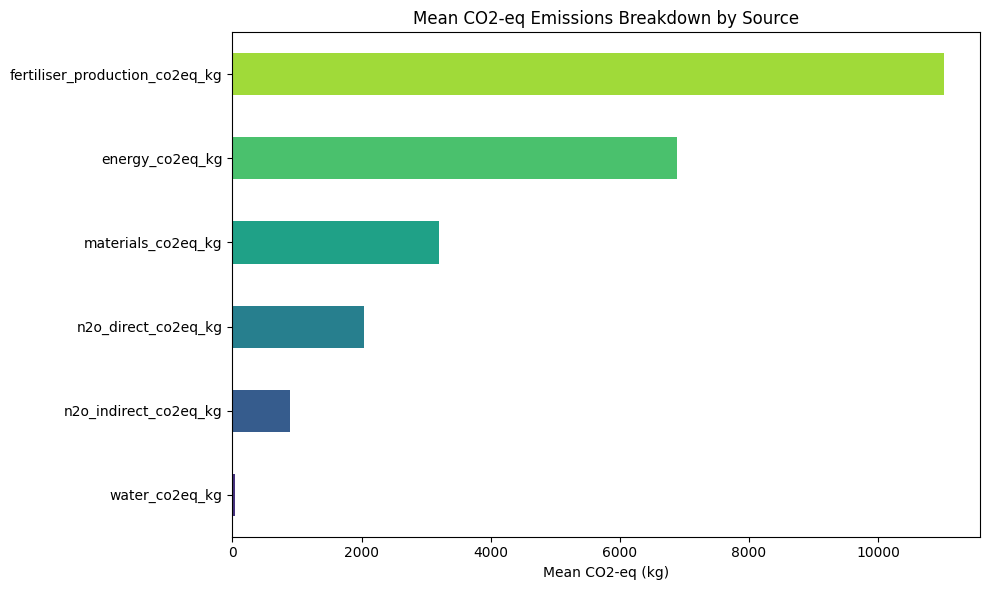

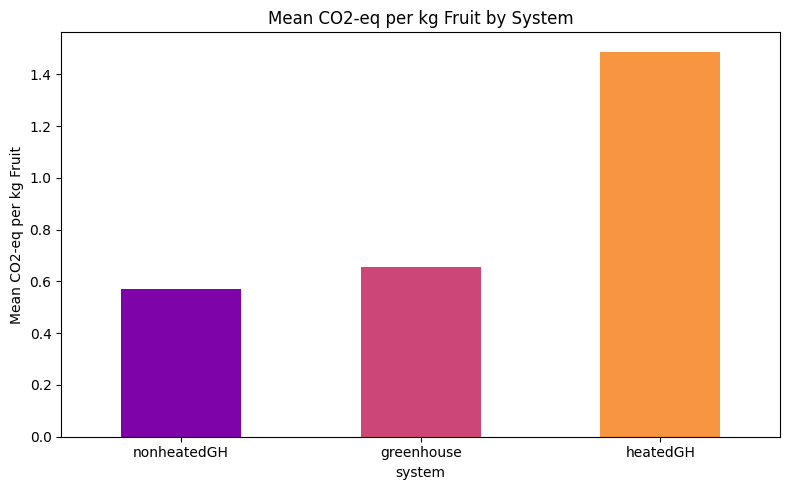

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if vis_data is not None:
    # Plot 1: Emissions breakdown
    emission_sources = vis_data['emission_sources']
    plt.figure(figsize=(10, 6))
    emission_sources.sort_values().plot(kind='barh', color=sns.color_palette('viridis', len(emission_sources)))
    plt.title('Mean CO2-eq Emissions Breakdown by Source')
    plt.xlabel('Mean CO2-eq (kg)')
    plt.tight_layout()
    plt.show()

    # Plot 2: System intensity
    system_intensity = vis_data['system_intensity']
    plt.figure(figsize=(8, 5))
    system_intensity.sort_values().plot(kind='bar', color=sns.color_palette('plasma', len(system_intensity)))
    plt.title('Mean CO2-eq per kg Fruit by System')
    plt.ylabel('Mean CO2-eq per kg Fruit')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [ ]:
# Calculate uncertainty parameters (GSD²) for SimaPro Monte Carlo.

def calculate_uncertainty_for_simapro(results_df):


    df = results_df.copy()

    # Calculate per-kg values
    df['N_per_kg'] = df['fertiliser_n_kg'] / df['yield_kg']
    df['P2O5_per_kg'] = df['fertiliser_p2o5_kg'] / df['yield_kg']
    df['K2O_per_kg'] = df['fertiliser_k2o_kg'] / df['yield_kg']
    df['elec_per_kg'] = df['electricity_kwh'] / df['yield_kg']
    df['diesel_per_kg'] = df['diesel_l'] / df['yield_kg']
    df['plastic_per_kg'] = df['plastic_m2'] / df['yield_kg'] * 0.15
    df['fleece_per_kg'] = df['fleece_m2'] / df['yield_kg'] * 0.08
    df['coir_per_kg'] = df['coir_kg'] / df['yield_kg']
    df['water_per_kg'] = df['total_water_m3'] / df['yield_kg']
    df['transport_per_kg'] = df['transport_tkm'] / df['yield_kg']
    df['yield_per_ha'] = df['yield_kg'] / df['area_ha']

    per_kg_cols = [col for col in df.columns if '_per_kg' in col] + ['yield_per_ha']

    stats = df.groupby(['system', 'year'])[per_kg_cols].agg(['mean', 'median', 'std', 'count'])

    results = []

    for (system, year) in stats.index:
        row = {'system': system, 'year': int(year)}

        for col in per_kg_cols:
            mean_val = stats.loc[(system, year), (col, 'mean')]
            median_val = stats.loc[(system, year), (col, 'median')]
            std_val = stats.loc[(system, year), (col, 'std')]
            n = stats.loc[(system, year), (col, 'count')]

            if mean_val > 0 and not np.isnan(std_val):
                cv = std_val / mean_val
            else:
                cv = 0

            if cv > 0:
                sigma = np.sqrt(np.log(1 + cv**2))
                gsd2 = np.exp(2 * sigma)
            else:
                gsd2 = 1.05

            col_short = col.replace('_per_kg', '').replace('_per_ha', '')
            row[f'{col_short}_median'] = median_val
            row[f'{col_short}_cv'] = cv
            row[f'{col_short}_gsd2'] = gsd2
            row[f'{col_short}_n'] = n

        results.append(row)

    return pd.DataFrame(results)


def print_simapro_parameters(uncertainty_df, system, year):
    """
    Print formatted parameters for entering into SimaPro.
    """
    row = uncertainty_df[(uncertainty_df['system'] == system) &
                          (uncertainty_df['year'] == year)].iloc[0]


    print(f"SIMAPRO PARAMETERS: {system} {int(year)}")


    print(f"\n{'Parameter':<20} {'Median':<12} {'GSD²':<10} {'CV':<10} {'n':<6}")
    print("-" * 70)

    params = ['N', 'P2O5', 'K2O', 'elec', 'diesel', 'plastic', 'fleece',
              'coir', 'water', 'transport', 'yield']

    for p in params:
        median = row.get(f'{p}_median', 0)
        gsd2 = row.get(f'{p}_gsd2', 1)
        cv = row.get(f'{p}_cv', 0)
        n = row.get(f'{p}_n', 0)

        if median > 0:
            print(f"{p:<20} {median:<12.6f} {gsd2:<10.4f} {cv:<10.2%} {int(n):<6}")


    print("\nGSD² interpretation: 1.0-1.2 very low | 1.2-1.5 low | 1.5-2.0 moderate | >2.0 high")

In [ ]:
# Calculate uncertainty for SimaPro
uncertainty_df = calculate_uncertainty_for_simapro(results_df)

# Print for all systems (using 2020 as example year)
print_simapro_parameters(uncertainty_df, 'greenhouse', 2020)
print_simapro_parameters(uncertainty_df, 'heatedGH', 2020)
print_simapro_parameters(uncertainty_df, 'nonheatedGH', 2020)

# Export
uncertainty_df.to_excel('simapro_uncertainty_parameters.xlsx', index=False)
print("\nExported to: simapro_uncertainty_parameters.xlsx")
files.download('simapro_uncertainty_parameters.xlsx')

SIMAPRO PARAMETERS: greenhouse 2020

Parameter            Median       GSD²       CV         n     
----------------------------------------------------------------------
N                    0.013327     7.5731     133.66%    16    
P2O5                 0.004019     7.9021     138.21%    16    
K2O                  0.008109     9.8559     164.37%    16    
elec                 0.235979     2.7029     52.95%     16    
diesel               0.022305     2.7029     52.95%     16    
plastic              0.012543     2.7029     52.95%     16    
fleece               0.003034     2.7029     52.95%     16    
coir                 0.048940     2.7066     53.03%     16    
water                0.518178     2.9223     57.71%     16    
transport            0.339697     4.4932     87.09%     16    
yield                49865.939655 2.0866     38.06%     16    

GSD² interpretation: 1.0-1.2 very low | 1.2-1.5 low | 1.5-2.0 moderate | >2.0 high
SIMAPRO PARAMETERS: heatedGH 2020

Parameter        

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Print parameters for ALL system-year combinations
for system in ['greenhouse', 'heatedGH', 'nonheatedGH']:
    for year in [2020, 2021, 2022, 2023]:
        try:
            print_simapro_parameters(uncertainty_df, system, year)
        except:
            print(f"\n{system} {year}: No data")




SIMAPRO PARAMETERS: greenhouse 2020

Parameter            Median       GSD²       CV         n     
----------------------------------------------------------------------
N                    0.013327     7.5731     133.66%    16    
P2O5                 0.004019     7.9021     138.21%    16    
K2O                  0.008109     9.8559     164.37%    16    
elec                 0.235979     2.7029     52.95%     16    
diesel               0.022305     2.7029     52.95%     16    
plastic              0.012543     2.7029     52.95%     16    
fleece               0.003034     2.7029     52.95%     16    
coir                 0.048940     2.7066     53.03%     16    
water                0.518178     2.9223     57.71%     16    
transport            0.339697     4.4932     87.09%     16    
yield                49865.939655 2.0866     38.06%     16    

GSD² interpretation: 1.0-1.2 very low | 1.2-1.5 low | 1.5-2.0 moderate | >2.0 high
SIMAPRO PARAMETERS: greenhouse 2021

Parameter      

In [ ]:
# Calculate land use per kg for each system-year (for SimaPro)
land_use_by_year = results_df.groupby(['system', 'year']).agg({
    'area_ha': 'sum',
    'yield_kg': 'sum'
})

land_use_by_year['area_m2'] = land_use_by_year['area_ha'] * 10000
land_use_by_year['land_use_m2_per_kg'] = land_use_by_year['area_m2'] / land_use_by_year['yield_kg']

print("="*60)
print("LAND USE PER KG (m²a/kg) - FOR SIMAPRO")
print("="*60)
print(land_use_by_year[['area_ha', 'yield_kg', 'land_use_m2_per_kg']].round(4))
print("\n")
print("="*60)
print("VALUES TO ENTER IN SIMAPRO (Occupation, annual crop, GB)")
print("="*60)
print(land_use_by_year['land_use_m2_per_kg'].round(4))

LAND USE PER KG (m²a/kg) - FOR SIMAPRO
                    area_ha      yield_kg  land_use_m2_per_kg
system      year                                             
greenhouse  2020.0   47.290  2.090276e+06              0.2262
            2021.0   47.100  2.157758e+06              0.2183
            2022.0   47.140  2.191934e+06              0.2151
            2023.0   46.855  2.001628e+06              0.2341
heatedGH    2020.0    1.400  7.755900e+04              0.1805
            2021.0    1.400  6.387500e+04              0.2192
            2022.0    1.400  4.388500e+04              0.3190
            2023.0    1.400  4.343871e+04              0.3223
nonheatedGH 2020.0    2.000  6.947700e+04              0.2879
            2021.0    2.000  1.017560e+05              0.1965
            2022.0    2.000  8.219600e+04              0.2433
            2023.0    2.000  1.021283e+05              0.1958


VALUES TO ENTER IN SIMAPRO (Occupation, annual crop, GB)
system       year  
greenhouse   2